# 3 · Trim

Level flight, climbs and coordinated turns of the 747 model.
Lesson: [03](../docs/lessons/03-trim.md) · Theory: [trim](../docs/trim.md).

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt
from flightdyn import plotting as P

P.use_style()
np.set_printoptions(precision=4, suppress=True)
sys.path.insert(0, "../validation")  # cited reference data and reference aircraft
from reference_aircraft import b747, b747_condition, navion, navion_condition
from flightdyn.trim_solver import trim, trim_guess
from flightdyn.units import KT, LBF

In [2]:
ac, c = b747(2), b747_condition(2)
t = trim(ac, c["V"], c["h"])
print(f"alpha {np.degrees(t.alpha):.2f} deg (published {np.degrees(c['alpha']):.2f}), "
      f"elevator {np.degrees(t.de):.2f} deg, thrust {t.thrust / LBF:.0f} lbf, "
      f"residual {t.residual:.1e}")
t = trim(ac, c["V"], c["h"], gamma=np.radians(3.0))
print(f"3 deg climb: alpha {np.degrees(t.alpha):.2f} deg, thrust {t.thrust / LBF:.0f} lbf")

alpha 5.62 deg (published 5.70), elevator 0.08 deg, thrust 51554 lbf, residual 1.8e-15
3 deg climb: alpha 5.46 deg, thrust 80437 lbf


## Trim curve: elevator against speed (speed stability)

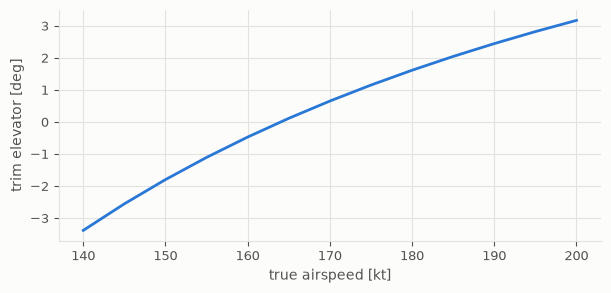

In [3]:
kt = np.linspace(140, 200, 13)
guess, rows = None, []
for v in kt:
    t = trim(ac, v * KT, 0.0, guess=guess)
    guess = trim_guess(t, ac.weight)
    rows.append((np.degrees(t.alpha), np.degrees(t.de)))
rows = np.array(rows)
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(kt, rows[:, 1])
ax.set_xlabel("true airspeed [kt]")
ax.set_ylabel("trim elevator [deg]");

## Coordinated level turns

In [4]:
for rate in (1.0, 2.0, 3.0):
    t = trim(ac, c["V"], 0.0, turn_rate=np.radians(rate))
    print(f"{rate:.0f} deg/s: bank {np.degrees(t.phi):5.1f} deg, n = {1 / np.cos(t.phi):.3f}, "
          f"elevator {np.degrees(t.de):+.2f} deg, rudder {np.degrees(t.controls[2]):+.2f} deg")

1 deg/s: bank   8.8 deg, n = 1.012, elevator -0.13 deg, rudder -0.99 deg
2 deg/s: bank  17.2 deg, n = 1.047, elevator -0.75 deg, rudder -1.91 deg
3 deg/s: bank  24.9 deg, n = 1.102, elevator -1.72 deg, rudder -2.71 deg
